In [ ]:
import sys
sys.path.append('./dev')

In [5]:
from dataclasses import asdict
import secondary_two_units_reference as su
from secondary_two_units_reference import *

In [6]:
# Demonstration and verification. Two admissible units sharing an event.
u1 = Unit(mean_loss=200.0, sd_indep=100.0, sd_corr=150.0, max_loss=1000.0)
u2 = Unit(mean_loss=500.0, sd_indep=300.0, sd_corr=200.0, max_loss=2000.0)
bs, n1, n2 = 10.0, 101, 201

In [7]:
res = secondary_two_units([u1, u2], bs, n1, n2)

In [10]:
m = res.meta
print("alpha:", m["alpha"], "\nbeta:", m["beta"])
print(f"total mass          {m['total_mass']:.15f}")
print(f"grid means          {m['grid_mean'][0]:9.4f} {m['grid_mean'][1]:9.4f}"
      f"   analytic {m['analytic_mean'][0]:.1f} {m['analytic_mean'][1]:.1f}")
print(f"grid sds            {m['grid_sd'][0]:9.4f} {m['grid_sd'][1]:9.4f}"
      f"   sigma_I + sigma_C {u1.sd_indep + u1.sd_corr:.1f} "
      f"{u2.sd_indep + u2.sd_corr:.1f}")
print(f"copula normal corr  {m['copula_normal_correlation']:.6f}")
print(f"grid loss corr      {m['grid_correlation']:.6f}")
xs, ps = res.sum_distribution()
print(f"sum: mass {ps.sum():.15f}  mean {ps @ xs:9.4f}"
      f"  (unit means sum to {u1.mean_loss + u2.mean_loss:.1f})")

alpha: (0.31200000000000006, 0.5) 
beta: (1.2480000000000002, 1.5)
total mass          1.000000000000000
grid means           199.8504  499.9264   analytic 200.0 500.0
grid sds             250.1190  500.0241   sigma_I + sigma_C 250.0 500.0
copula normal corr  0.461538
grid loss corr      0.410992
sum: mass 1.000000000000000  mean  699.7768  (unit means sum to 700.0)


In [13]:
# Marginals of the joint against directly bucketed betas.
for unit, n, axis in ((u1, n1, 1), (u2, n2, 2)):
    prep = su._prepare(unit, f"unit {axis}", "clamp", DEFAULT_CLAMP_FACTOR)
    edges = (np.arange(n + 1) - 0.5) * bs
    direct = np.diff(beta_dist.cdf(edges / prep.max_loss,
                                   prep.alpha, prep.beta))
    err = np.abs(res.marginal(axis) - direct).max()
    print(f"unit {axis} marginal vs direct beta bucketing: max abs err {err:.2e}")

unit 1 marginal vs direct beta bucketing: max abs err 4.32e-05
unit 2 marginal vs direct beta bucketing: max abs err 1.94e-05


In [14]:
# Independence sanity check: no correlated sd gives an outer product.
ind = secondary_two_units([u1._replace(sd_corr=0.0),
                           u2._replace(sd_corr=0.0)], bs, n1, n2)
outer = np.outer(ind.marginal(1), ind.marginal(2))
print(f"sd_corr = 0: pmf vs outer product: max abs err "
      f"{np.abs(ind.pmf - outer).max():.2e}")

sd_corr = 0: pmf vs outer product: max abs err 1.45e-17


In [15]:
# Comonotone path: unit 1 with no independent sd.
com = secondary_two_units([u1._replace(sd_indep=0.0), u2], bs, n1, n2)
print(f"comonotone unit 1: mass {com.meta['total_mass']:.12f}  "
      f"grid corr {com.meta['grid_correlation']:.4f}")

comonotone unit 1: mass 1.000000000000  grid corr 0.5239


In [18]:
# Monte Carlo cross-check of the full joint.
mc = su._monte_carlo([u1, u2], bs, n1, n2)
print(f"Monte Carlo (2e6 sims): max abs cell err "
      f"{np.abs(res.pmf - mc).max():.2e}, "
      f"mean abs {np.abs(res.pmf - mc).mean():.2e}")

Monte Carlo (2e6 sims): max abs cell err 1.93e-04, mean abs 3.02e-06


In [24]:
import matplotlib.pyplot as plt
import numpy as np 

In [48]:
def plot(resm, log):
    if log:
        X = np.log(res.pmf)
    else:
        X = res.pmf
    x2, x1 = res.x1, res.x2
    extent = [x1.min(), x1.max(), x2.min(), x2.max()]

    fig, ax = plt.subplots(figsize=(6,6))
    
    im = ax.imshow(
        X, 
        extent=extent, 
        origin='lower', 
        aspect='auto', 
        cmap='viridis'
    )
    
    X_grid, Y_grid = np.meshgrid(x1, x2)
    contours = ax.contour(X_grid, Y_grid, X, levels=20, 
                          colors='white', alpha=0.5)
    ax.clabel(contours, inline=True, fontsize=8)
    ax.set(aspect='equal')
    fig.colorbar(im, ax=ax)

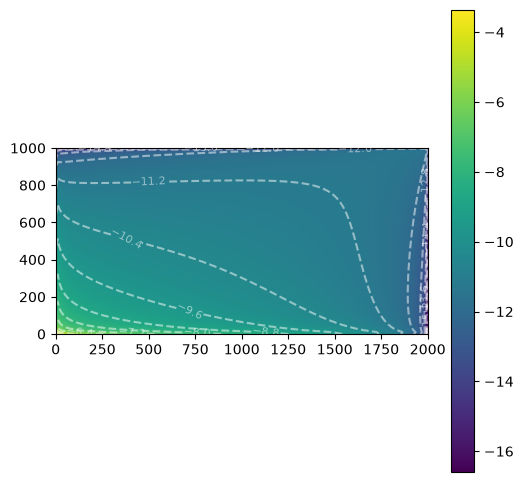

In [49]:
plot(res, log=True)